In [1]:
%cd ..
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load

df = load()
df.head()

/Users/lakshyashetty/Projects/fraud-detection


,step,type,amount,nameOrig,nameDest,isFraud,isFlaggedFraud
0,1,TRANSFER,181.00,C1305486145,C553264065,1,0
1,1,CASH_OUT,181.00,C840083671,C38997010,1,0
2,1,CASH_OUT,229133.94,C905080434,C476402209,0,0
3,1,TRANSFER,215310.30,C1670993182,C1100439041,0,0
4,1,TRANSFER,311685.89,C1984094095,C932583850,0,0


In [2]:
# Q1: How rare is fraud?
df["isFraud"].value_counts(normalize=True)

isFraud
0    0.997035
1    0.002965
Name: proportion, dtype: float64

A model that always says “not fraud” would be 99.7% accurate, so accuracy is useless here. I’ll use PR-AUC and recall instead.

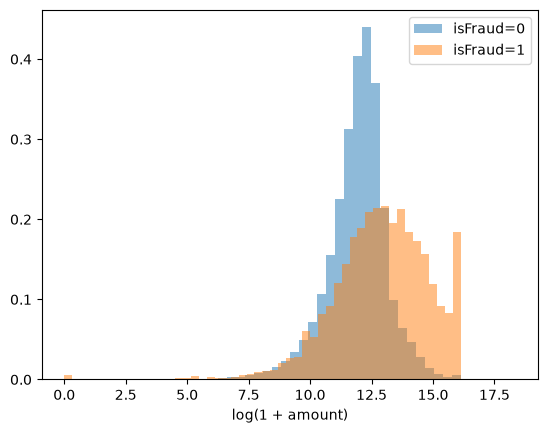

In [3]:
# Q2: Do fraud amounts look different?
for label, g in df.groupby("isFraud"):
    plt.hist(np.log1p(g["amount"]), bins=50, alpha=0.5, density=True, label=f"isFraud={label}")
plt.xlabel("log(1 + amount)"); plt.legend(); plt.show()

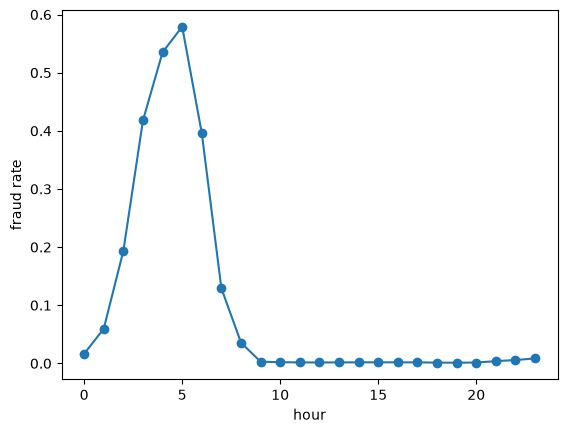

In [4]:
# Q3: Does fraud happen at certain hours?
df.assign(hour=df["step"] % 24).groupby("hour")["isFraud"].mean().plot(marker="o")
plt.ylabel("fraud rate"); plt.show()

In [5]:
# Q4: How good is the old rule?
print(pd.crosstab(df["isFlaggedFraud"], df["isFraud"]))
caught = df.loc[df["isFraud"] == 1, "isFlaggedFraud"].mean()
print(f"Old rule catches {caught:.2%} of fraud")

isFraud               0     1
isFlaggedFraud               
0               2762196  8197
1                     0    16
Old rule catches 0.19% of fraud


In [6]:
# Q5: Do accounts repeat?
print("Senders:", df["nameOrig"].value_counts().head(3), sep="\n")
print("Receivers:", df["nameDest"].value_counts().head(3), sep="\n")

Senders:
nameOrig
C2098525306    3
C1902386530    3
C724452879     3
Name: count, dtype: int64[pyarrow]
Receivers:
nameDest
C1286084959    75
C665576141     68
C1360767589    68
Name: count, dtype: int64[pyarrow]


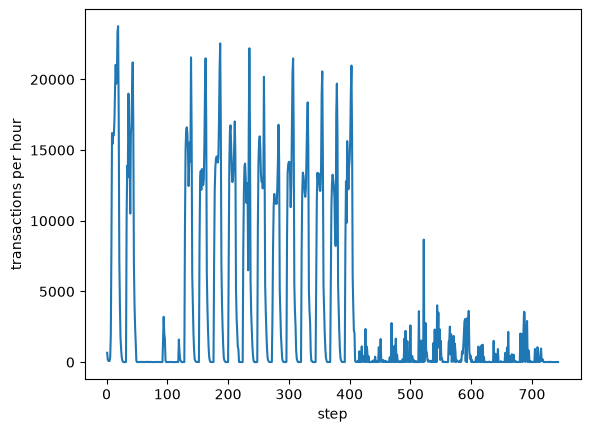

In [7]:
# Q6: How does volume change over time?
df.groupby("step").size().plot(); plt.ylabel("transactions per hour"); plt.show()

In [8]:
split = pd.cut(df["step"], [0, 500, 600, 744], labels=["train", "valid", "test"])
df.groupby(split, observed=True)["isFraud"].agg(rows="size", frauds="sum", fraud_rate="mean")

,rows,frauds,fraud_rate
step,,,
train,2645779,5561,0.002102
valid,81080,1052,0.012975
test,43550,1600,0.036739


In [9]:
split = pd.cut(df["step"], [0, 300, 350, 400, 744], labels=["train", "valid", "test", "stress"])
df.groupby(split, observed=True)["isFraud"].agg(rows="size", frauds="sum", fraud_rate="mean")

,rows,frauds,fraud_rate
step,,,
train,1780544,3401,0.001910
valid,380409,500,0.001314
test,368583,576,0.001563
stress,240873,3736,0.015510
